# Where does a parameter gradient live?

**Question:** What exactly is stored in an `nn.Parameter` and its `.grad` field?

A parameter is a leaf tensor whose value participates in the forward computation. Think of
`.grad` as a separate accumulation slot attached to that leaf: it starts absent, and
`backward()` adds the parameter's gradient into it.

We will make one prediction for each of three examples using two weights and one bias. The
numbers are deliberately small enough to inspect and differentiate by hand.

In [1]:
import torch
from IPython.display import SVG, display
from rich.console import Console
from rich.table import Table
from torch import nn

from ml_sandbox.plotting import chart_to_svg, grouped_bar_chart

torch.manual_seed(7)
torch.set_printoptions(precision=4)
console = Console(force_jupyter=True, width=100)

## 1. A concrete forward computation

The forward rule is visible in one line: `prediction = inputs @ weight + bias`. No layer
object is hiding the parameters or the arithmetic.

In [2]:
inputs = torch.tensor([[1.0, 2.0], [-1.0, 1.0], [2.0, -1.0]])
targets = torch.tensor([-1.0, 0.0, 2.0])

weight = nn.Parameter(torch.tensor([0.5, -1.0]))
bias = nn.Parameter(torch.tensor([0.25]))

prediction = inputs @ weight + bias
prediction.retain_grad()
loss = ((prediction - targets) ** 2).mean()

forward_table = Table(title="Forward state before backward")
forward_table.add_column("tensor")
forward_table.add_column("value")
forward_table.add_column("leaf?")
forward_table.add_column("requires grad?")
forward_table.add_column("grad_fn")
forward_table.add_column(".grad")

for name, tensor in (("weight", weight), ("bias", bias), ("prediction", prediction)):
    grad_fn = type(tensor.grad_fn).__name__ if tensor.grad_fn is not None else "None"
    gradient = str(tensor.grad) if tensor.grad is not None else "None"
    forward_table.add_row(
        name,
        str(tensor.detach().tolist()),
        str(tensor.is_leaf),
        str(tensor.requires_grad),
        grad_fn,
        gradient,
    )

console.print(forward_table)
console.print(f"prediction = {prediction.detach().tolist()}")
console.print(f"mean squared error = {loss.item():.4f}")

                            Forward state before backward                            
┏━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━┓
┃ tensor     ┃ value                ┃ leaf? ┃ requires grad? ┃ grad_fn      ┃ .grad ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━┩
│ weight     │ [0.5, -1.0]          │ True  │ True           │ None         │ None  │
│ bias       │ [0.25]               │ True  │ True           │ None         │ None  │
│ prediction │ [-1.25, -1.25, 2.25] │ False │ True           │ AddBackward0 │ None  │
└────────────┴──────────────────────┴───────┴────────────────┴──────────────┴───────┘

prediction = [-1.25, -1.25, 2.25]

mean squared error = 0.5625

`weight` and `bias` are leaves: they were created directly rather than produced by another
differentiable operation. `prediction` is not a leaf; its `grad_fn` points into the graph that
autograd will traverse. All three `.grad` slots are still `None` because no backward pass has
asked autograd to calculate a gradient.

For mean squared error over $N$ examples, the first derivative is
$\frac{\partial L}{\partial \hat{y}_i} = \frac{2}{N}(\hat{y}_i-y_i)$. Each example
then contributes that scalar times its input vector to the weight gradient.

## 2. Backward fills the accumulation slots

We retain `prediction.grad` only for inspection. Non-leaf gradients are normally discarded
after they have been used to propagate gradients farther backward. Parameter gradients, by
contrast, are retained automatically.

In [3]:
loss.backward()

assert weight.grad is not None
assert bias.grad is not None
assert prediction.grad is not None

manual_prediction_grad = 2 * (prediction.detach() - targets) / prediction.numel()
per_example_weight_grad = manual_prediction_grad[:, None] * inputs
manual_weight_grad = per_example_weight_grad.sum(dim=0)
manual_bias_grad = manual_prediction_grad.sum().reshape_as(bias)

torch.testing.assert_close(prediction.grad, manual_prediction_grad)
torch.testing.assert_close(weight.grad, manual_weight_grad)
torch.testing.assert_close(bias.grad, manual_bias_grad)

gradient_table = Table(title="Autograd agrees with the hand-derived gradients")
gradient_table.add_column("parameter")
gradient_table.add_column("value")
gradient_table.add_column("autograd .grad")
gradient_table.add_column("manual gradient")
gradient_table.add_row(
    "weight",
    str(weight.detach().tolist()),
    str(weight.grad.tolist()),
    str(manual_weight_grad.tolist()),
)
gradient_table.add_row(
    "bias",
    str(bias.detach().tolist()),
    str(bias.grad.tolist()),
    str(manual_bias_grad.tolist()),
)
console.print(gradient_table)
console.print(f"retained prediction.grad = {prediction.grad.tolist()}")

                   Autograd agrees with the hand-derived gradients                   
┏━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ parameter ┃ value       ┃ autograd .grad             ┃ manual gradient            ┃
┡━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ weight    │ [0.5, -1.0] │ [1.0, -1.3333333730697632] │ [1.0, -1.3333332538604736] │
│ bias      │ [0.25]      │ [-0.8333333134651184]      │ [-0.8333333134651184]      │
└───────────┴─────────────┴────────────────────────────┴────────────────────────────┘

retained prediction.grad = [-0.1666666716337204, -0.8333333730697632, 0.1666666716337204]

The value tensor and gradient tensor are distinct objects with matching shape, dtype, and
device. The optimizer will later read `.grad`; the backward pass does not update the
parameter value itself.

In [4]:
storage_table = Table(title="A parameter and its gradient are separate tensors")
storage_table.add_column("property")
storage_table.add_column("weight")
storage_table.add_column("weight.grad")
storage_table.add_row("shape", str(tuple(weight.shape)), str(tuple(weight.grad.shape)))
storage_table.add_row("dtype", str(weight.dtype), str(weight.grad.dtype))
storage_table.add_row("device", str(weight.device), str(weight.grad.device))
console.print(storage_table)

assert weight.grad is not weight
assert weight.grad.shape == weight.shape
assert weight.grad.dtype == weight.dtype
assert weight.grad.device == weight.device

 A parameter and its gradient are separate  
                  tensors                   
┏━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ property ┃ weight        ┃ weight.grad   ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ shape    │ (2,)          │ (2,)          │
│ dtype    │ torch.float32 │ torch.float32 │
│ device   │ cpu           │ cpu           │
└──────────┴───────────────┴───────────────┘

## 3. Each example contributes to the stored gradient

The bars below are the three examples' signed contributions. The final bar in each group is
their sum: exactly the value autograd placed in the corresponding `.grad` element.

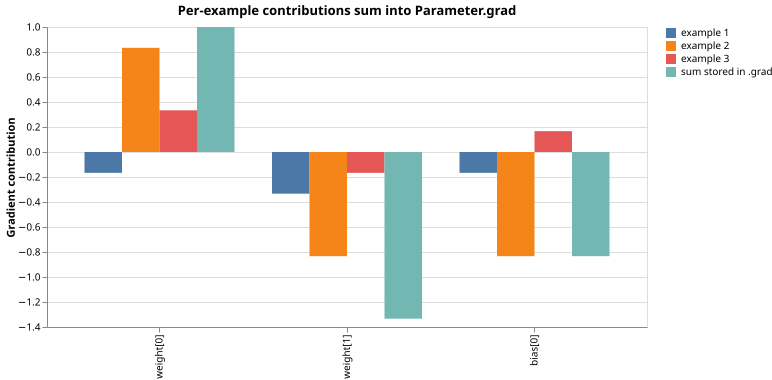

In [5]:
contribution_series = {
    f"example {index + 1}": [
        *per_example_weight_grad[index].tolist(),
        manual_prediction_grad[index].item(),
    ]
    for index in range(inputs.shape[0])
}
contribution_series["sum stored in .grad"] = [
    *manual_weight_grad.tolist(),
    manual_bias_grad.item(),
]

contribution_chart = grouped_bar_chart(
    ["weight[0]", "weight[1]", "bias[0]"],
    contribution_series,
    title="Per-example contributions sum into Parameter.grad",
    y_title="Gradient contribution",
)
display(SVG(chart_to_svg(contribution_chart)))

## 4. Experiment: run backward twice

A backward pass **adds** into an existing parameter gradient. Rebuilding the same forward
graph and calling `backward()` again should therefore double both parameter gradients.

In [6]:
first_weight_grad = weight.grad.detach().clone()
first_bias_grad = bias.grad.detach().clone()

prediction_again = inputs @ weight + bias
loss_again = ((prediction_again - targets) ** 2).mean()
loss_again.backward()

torch.testing.assert_close(weight.grad, 2 * first_weight_grad)
torch.testing.assert_close(bias.grad, 2 * first_bias_grad)

accumulation_table = Table(title="Repeated backward accumulates")
accumulation_table.add_column("parameter")
accumulation_table.add_column("after one backward")
accumulation_table.add_column("after two backwards")
accumulation_table.add_row(
    "weight.grad", str(first_weight_grad.tolist()), str(weight.grad.tolist())
)
accumulation_table.add_row("bias.grad", str(first_bias_grad.tolist()), str(bias.grad.tolist()))
console.print(accumulation_table)

                      Repeated backward accumulates                      
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ parameter   ┃ after one backward         ┃ after two backwards        ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ weight.grad │ [1.0, -1.3333333730697632] │ [2.0, -2.6666667461395264] │
│ bias.grad   │ [-0.8333333134651184]      │ [-1.6666666269302368]      │
└─────────────┴────────────────────────────┴────────────────────────────┘

## 5. Reset the slot, then calculate one gradient again

Assigning `None` says that no gradient is currently stored. This is different from keeping a
zero-filled gradient tensor: the absent state is explicit and lets PyTorch allocate the next
gradient normally.

In [7]:
weight.grad = None
bias.grad = None

assert weight.grad is None
assert bias.grad is None

prediction_after_reset = inputs @ weight + bias
loss_after_reset = ((prediction_after_reset - targets) ** 2).mean()
loss_after_reset.backward()

assert weight.grad is not None
assert bias.grad is not None
torch.testing.assert_close(weight.grad, first_weight_grad)
torch.testing.assert_close(bias.grad, first_bias_grad)

reset_table = Table(title="Reset removes accumulated history")
reset_table.add_column("parameter")
reset_table.add_column("new gradient after reset")
reset_table.add_column("original one-pass gradient")
reset_table.add_row("weight.grad", str(weight.grad.tolist()), str(first_weight_grad.tolist()))
reset_table.add_row("bias.grad", str(bias.grad.tolist()), str(first_bias_grad.tolist()))
console.print(reset_table)

                    Reset removes accumulated history                    
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ parameter   ┃ new gradient after reset   ┃ original one-pass gradient ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ weight.grad │ [1.0, -1.3333333730697632] │ [1.0, -1.3333333730697632] │
│ bias.grad   │ [-0.8333333134651184]      │ [-0.8333333134651184]      │
└─────────────┴────────────────────────────┴────────────────────────────┘

## What `Parameter.grad` measures

In plain language, `.grad` holds the sum of this parameter's loss gradients from every
backward pass since the slot was last cleared. It is a separate tensor attached to the leaf
parameter; it is not part of the parameter value, and it does not update that value by itself.
Non-leaf activations participate in the same chain rule, but their gradients are retained only
when explicitly requested.